# Homework 5: Decision Trees and Regression


USC ID: 1450125536  
Name: Yufan Yao  
GitHub: yufanyao-cloud  

In [6]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LassoCV, LinearRegression, RidgeCV
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import GridSearchCV, KFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, _tree, plot_tree
from xgboost import XGBRegressor

warnings.filterwarnings('ignore')

RANDOM_STATE = 552
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

sns.set_theme(style='whitegrid')

repo_root = Path.cwd().resolve()
if not (repo_root / 'data').exists():
    repo_root = repo_root.parent

data_dir = repo_root / 'data'


# 1. Decision Trees as Interpretable Models

## 1(a) Load data

There are two diagnosis columns in this data set. I combine the two yes/no outcomes into one label-powerset target. This lets one multiclass tree represent all diagnosis combinations.


In [7]:
names = [
    'temperature',
    'nausea',
    'lumbar_pain',
    'urine_pushing',
    'micturition_pain',
    'urethra_irritation',
    'bladder_inflammation',
    'renal_pelvis_nephritis',
]

diagnosis = pd.read_csv(
    data_dir / 'diagnosis.data',
    sep=r'\s+',
    header=None,
    names=names,
    encoding='utf-16',
    decimal=',',
)

features = names[:6]

y = (
    diagnosis['bladder_inflammation'].map(
        {'yes': 'bladder', 'no': 'no_bladder'}
    )
    + ' | '
    + diagnosis['renal_pelvis_nephritis'].map(
        {'yes': 'nephritis', 'no': 'no_nephritis'}
    )
)

encoder = ColumnTransformer(
    transformers=[
        (
            'binary',
            OrdinalEncoder(categories=[['no', 'yes']] * 5),
            features[1:],
        )
    ],
    remainder='passthrough',
    verbose_feature_names_out=False,
)

X = encoder.fit_transform(diagnosis[features])
feature_names = list(encoder.get_feature_names_out())

diagnosis.head()


,temperature,nausea,lumbar_pain,urine_pushing,micturition_pain,urethra_irritation,bladder_inflammation,renal_pelvis_nephritis
0,35.5,no,yes,no,no,no,no,no
1,35.9,no,no,yes,yes,yes,yes,no
2,35.9,no,yes,no,no,no,no,no
3,36.0,no,no,yes,yes,yes,yes,no
4,36.0,no,yes,no,no,no,no,no


## 1(b) Full decision tree

I fit the tree using all 120 observations, as required. I use entropy as the split criterion because it is the information-gain criterion used in the decision-tree reading.


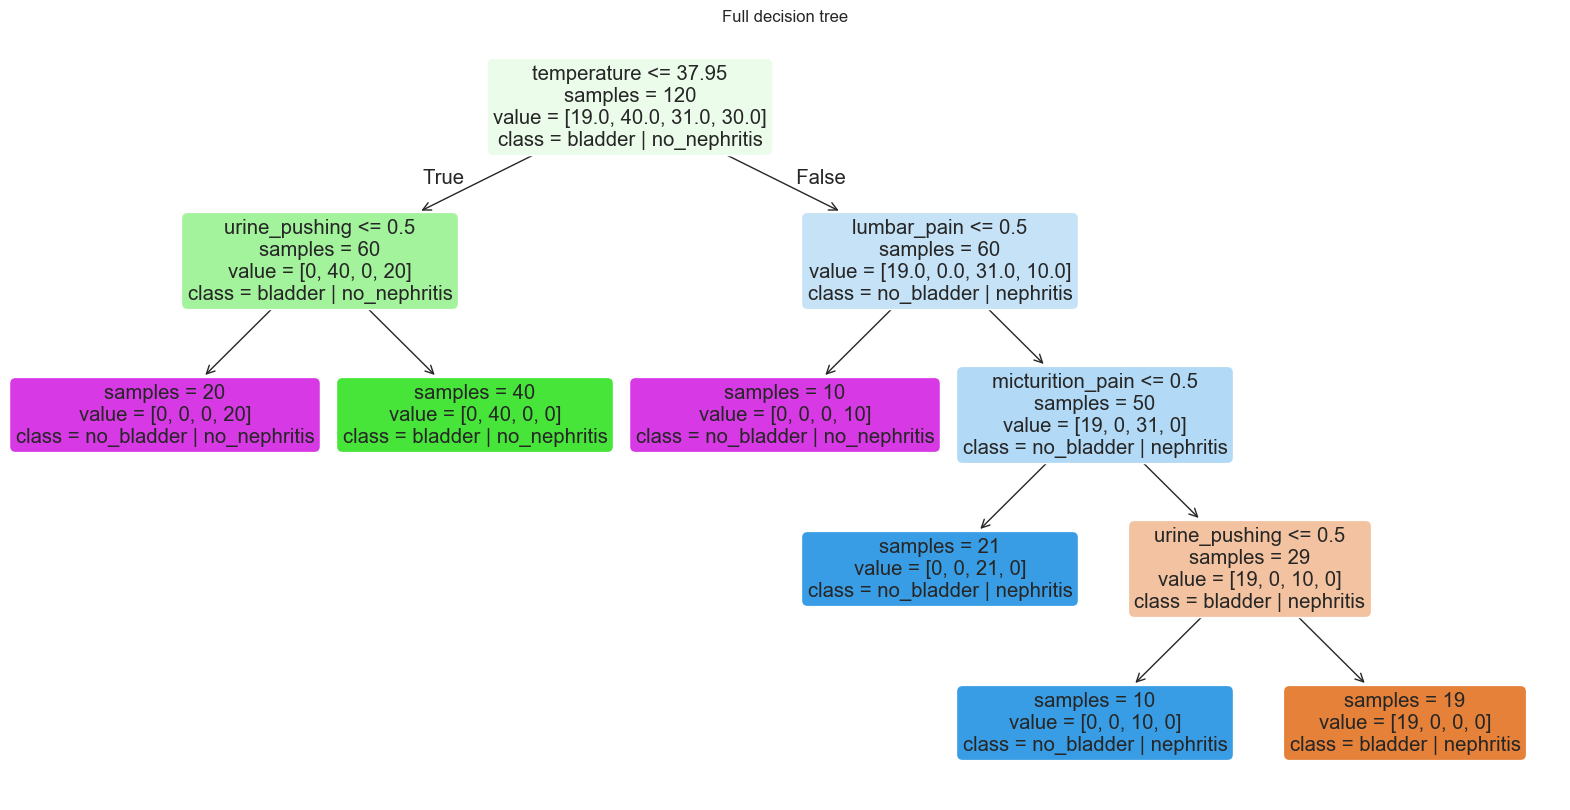

Depth: 4 Leaves: 6 Training accuracy: 1.0


In [8]:
full_tree = DecisionTreeClassifier(
    criterion='entropy',
    random_state=RANDOM_STATE,
)
full_tree.fit(X, y)

fig, ax = plt.subplots(figsize=(20, 10))

plot_tree(
    full_tree,
    feature_names=feature_names,
    class_names=full_tree.classes_,
    filled=True,
    rounded=True,
    impurity=False,
    ax=ax,
)

ax.set_title('Full decision tree')
plt.show()

print(
    'Depth:',
    full_tree.get_depth(),
    'Leaves:',
    full_tree.get_n_leaves(),
    'Training accuracy:',
    round(full_tree.score(X, y), 3),
)


## 1(c) IF-THEN rules

The function below starts at the root and follows every path to a leaf. Each completed path becomes one IF-THEN rule, so the tree can be read without referring to the plot.


In [9]:
def if_then_rules(model, names):
    tree = model.tree_
    rules = []

    def visit(node, conditions):
        if tree.feature[node] == _tree.TREE_UNDEFINED:
            label = model.classes_[np.argmax(tree.value[node][0])]
            condition_text = ' AND '.join(conditions) or 'TRUE'
            rules.append(
                f'IF {condition_text} THEN diagnosis = {label}'
            )
            return

        name = names[tree.feature[node]]
        threshold = tree.threshold[node]

        visit(
            tree.children_left[node],
            conditions + [f'{name} <= {threshold:.2f}'],
        )
        visit(
            tree.children_right[node],
            conditions + [f'{name} > {threshold:.2f}'],
        )

    visit(0, [])
    return rules


for number, rule in enumerate(if_then_rules(full_tree, feature_names), start=1):
    print(f'Rule {number}: {rule}')


Rule 1: IF temperature <= 37.95 AND urine_pushing <= 0.50 THEN diagnosis = no_bladder | no_nephritis
Rule 2: IF temperature <= 37.95 AND urine_pushing > 0.50 THEN diagnosis = bladder | no_nephritis
Rule 3: IF temperature > 37.95 AND lumbar_pain <= 0.50 THEN diagnosis = no_bladder | no_nephritis
Rule 4: IF temperature > 37.95 AND lumbar_pain > 0.50 AND micturition_pain <= 0.50 THEN diagnosis = no_bladder | nephritis
Rule 5: IF temperature > 37.95 AND lumbar_pain > 0.50 AND micturition_pain > 0.50 AND urine_pushing <= 0.50 THEN diagnosis = no_bladder | nephritis
Rule 6: IF temperature > 37.95 AND lumbar_pain > 0.50 AND micturition_pain > 0.50 AND urine_pushing > 0.50 THEN diagnosis = bladder | nephritis


## 1(d) Cost-complexity pruning

I get the candidate alpha values from the pruning path and compare them with five-fold cross-validation. I keep the smallest tree whose mean validation accuracy is within one standard error of the best candidate. This gives a shorter rule set without selecting a clearly worse model.


,ccp_alpha,mean_cv_accuracy,std_cv_accuracy,leaves,depth
0,0.0000,0.9833,0.0373,6,4
1,0.1996,0.8583,0.1003,4,2
2,0.3250,0.7417,0.1193,3,2
3,0.4591,0.6000,0.1520,2,1


Selected alpha: 0.0 Depth: 4 Leaves: 6


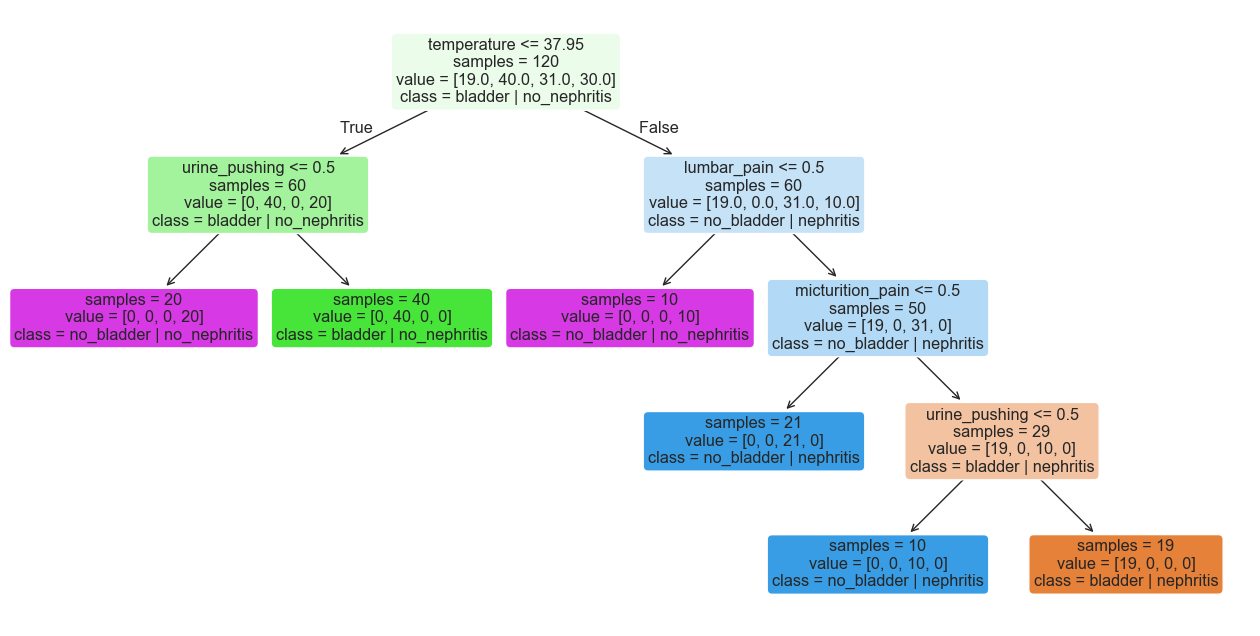

Pruned rule 1: IF temperature <= 37.95 AND urine_pushing <= 0.50 THEN diagnosis = no_bladder | no_nephritis
Pruned rule 2: IF temperature <= 37.95 AND urine_pushing > 0.50 THEN diagnosis = bladder | no_nephritis
Pruned rule 3: IF temperature > 37.95 AND lumbar_pain <= 0.50 THEN diagnosis = no_bladder | no_nephritis
Pruned rule 4: IF temperature > 37.95 AND lumbar_pain > 0.50 AND micturition_pain <= 0.50 THEN diagnosis = no_bladder | nephritis
Pruned rule 5: IF temperature > 37.95 AND lumbar_pain > 0.50 AND micturition_pain > 0.50 AND urine_pushing <= 0.50 THEN diagnosis = no_bladder | nephritis
Pruned rule 6: IF temperature > 37.95 AND lumbar_pain > 0.50 AND micturition_pain > 0.50 AND urine_pushing > 0.50 THEN diagnosis = bladder | nephritis


In [10]:
path = full_tree.cost_complexity_pruning_path(X, y)
rows = []

for alpha in np.unique(path.ccp_alphas[:-1]):
    candidate = DecisionTreeClassifier(
        criterion='entropy',
        random_state=RANDOM_STATE,
        ccp_alpha=float(alpha),
    )

    scores = cross_val_score(
        candidate,
        X,
        y,
        cv=cv,
        scoring='accuracy',
    )

    candidate.fit(X, y)

    rows.append(
        [
            alpha,
            scores.mean(),
            scores.std(ddof=1),
            candidate.get_n_leaves(),
            candidate.get_depth(),
        ]
    )

pruning = pd.DataFrame(
    rows,
    columns=[
        'ccp_alpha',
        'mean_cv_accuracy',
        'std_cv_accuracy',
        'leaves',
        'depth',
    ],
)

best = pruning.loc[pruning.mean_cv_accuracy.idxmax()]
eligible = pruning[
    pruning.mean_cv_accuracy
    >= best.mean_cv_accuracy - best.std_cv_accuracy / np.sqrt(5)
]

selected_alpha = eligible.sort_values(
    ['leaves', 'depth', 'ccp_alpha']
).iloc[0].ccp_alpha

pruned = DecisionTreeClassifier(
    criterion='entropy',
    random_state=RANDOM_STATE,
    ccp_alpha=selected_alpha,
)
pruned.fit(X, y)

display(pruning.round(4))

print(
    'Selected alpha:',
    selected_alpha,
    'Depth:',
    pruned.get_depth(),
    'Leaves:',
    pruned.get_n_leaves(),
)

fig, ax = plt.subplots(figsize=(16, 8))

plot_tree(
    pruned,
    feature_names=feature_names,
    class_names=pruned.classes_,
    filled=True,
    rounded=True,
    impurity=False,
    ax=ax,
)

plt.show()

for number, rule in enumerate(if_then_rules(pruned, feature_names), start=1):
    print(f'Pruned rule {number}: {rule}')


# 2. LASSO and Boosting for Regression

## 2(a)-(b) Load, split, and impute

I use rows 1-1495 for training and all remaining rows for testing. The variables state, county, community, communityname, and fold are excluded because the data description identifies them as nonpredictive. Missing values are replaced by the training-set median, then the same fitted imputer is applied to the test set.


In [11]:
attribute_names = [
    line.split()[1]
    for line in (data_dir / 'communities.names').read_text().splitlines()
    if line.strip().startswith('@attribute')
]

crime = pd.read_csv(
    data_dir / 'communities.data',
    header=None,
    names=attribute_names,
    na_values='?',
)

nonpredictive = [
    'state',
    'county',
    'community',
    'communityname',
    'fold',
]

target = 'ViolentCrimesPerPop'

predictors = [
    name
    for name in attribute_names
    if name not in nonpredictive + [target]
]

X_raw = crime[predictors].apply(pd.to_numeric, errors='coerce')
y_all = crime[target].astype(float)

X_train_raw = X_raw.iloc[:1495]
X_test_raw = X_raw.iloc[1495:]

y_train = y_all.iloc[:1495]
y_test = y_all.iloc[1495:]

imputer = SimpleImputer(strategy='median')

X_train = pd.DataFrame(
    imputer.fit_transform(X_train_raw),
    columns=predictors,
    index=X_train_raw.index,
)

X_test = pd.DataFrame(
    imputer.transform(X_test_raw),
    columns=predictors,
    index=X_test_raw.index,
)

print(
    'Data:',
    crime.shape,
    'Predictors:',
    len(predictors),
    'Missing train values:',
    X_train_raw.isna().sum().sum(),
)


Data: (1994, 128) Predictors: 122 Missing train values: 27633


## 2(c) Correlation matrix

The heatmap is based on the imputed training predictors. I hide the dense tick labels so the overall correlation pattern is easier to see.


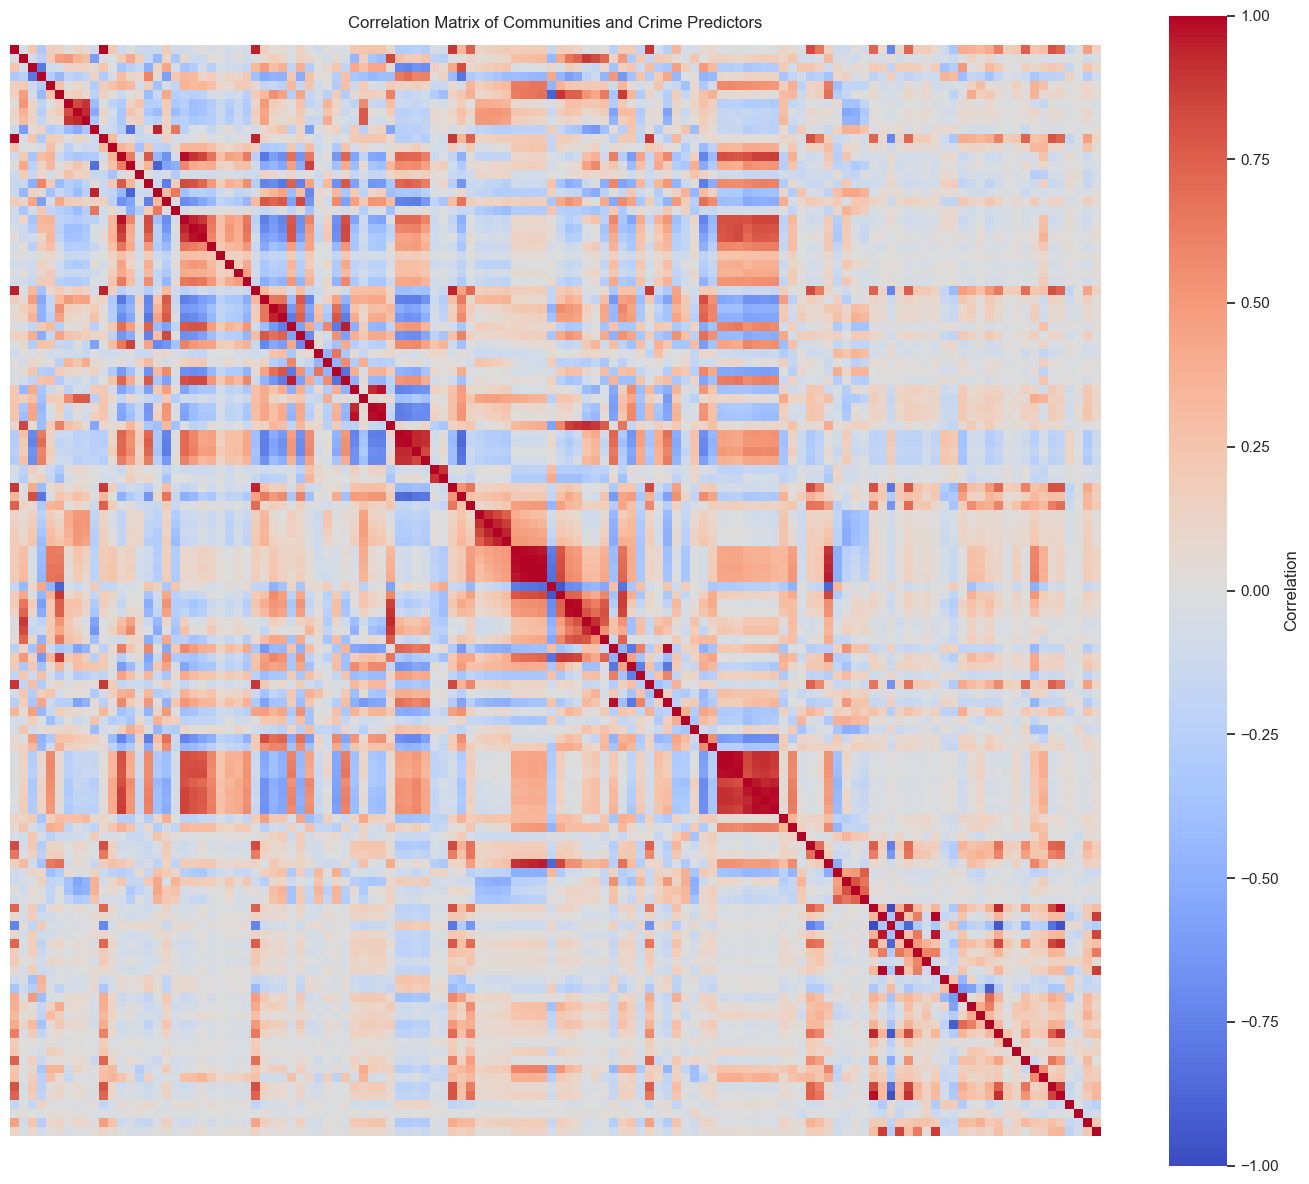

In [16]:
correlation_matrix = X_train.corr()

fig, ax = plt.subplots(figsize=(14, 12))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    xticklabels=False,
    yticklabels=False,
    cbar_kws={"label": "Correlation"},
    ax=ax,
)

ax.set_title(
    "Correlation Matrix of Communities and Crime Predictors",
    pad=12,
)

plt.tight_layout()
plt.show()

## 2(d)-(e) Coefficient of variation and plots

For each predictor, I calculate
$$
CV = \frac{s}{m}
$$
where $s$ is the sample standard deviation and $m$ is the sample mean. The assignment asks for
$$
\left\lfloor \sqrt{128} \right\rfloor = 11
$$
features with the largest CV values. I first list these 11 features, then make scatter plots to compare each feature with `ViolentCrimesPerPop`. The box plots show the distribution and possible outliers for the same features.

A visible trend in a scatter plot can be useful for exploration, but it is not enough to claim that a feature is statistically significant.

,feature,CV
0,PctPolicAsian,5.5271
1,NumStreet,4.2929
2,NumInShelters,3.4710
3,NumIlleg,3.0590
4,NumImmig,2.9266
5,LemasPctOfficDrugUn,2.5529
6,NumUnderPov,2.3424
7,LemasSwornFT,2.2480
8,population,2.2411
9,numbUrban,2.0385


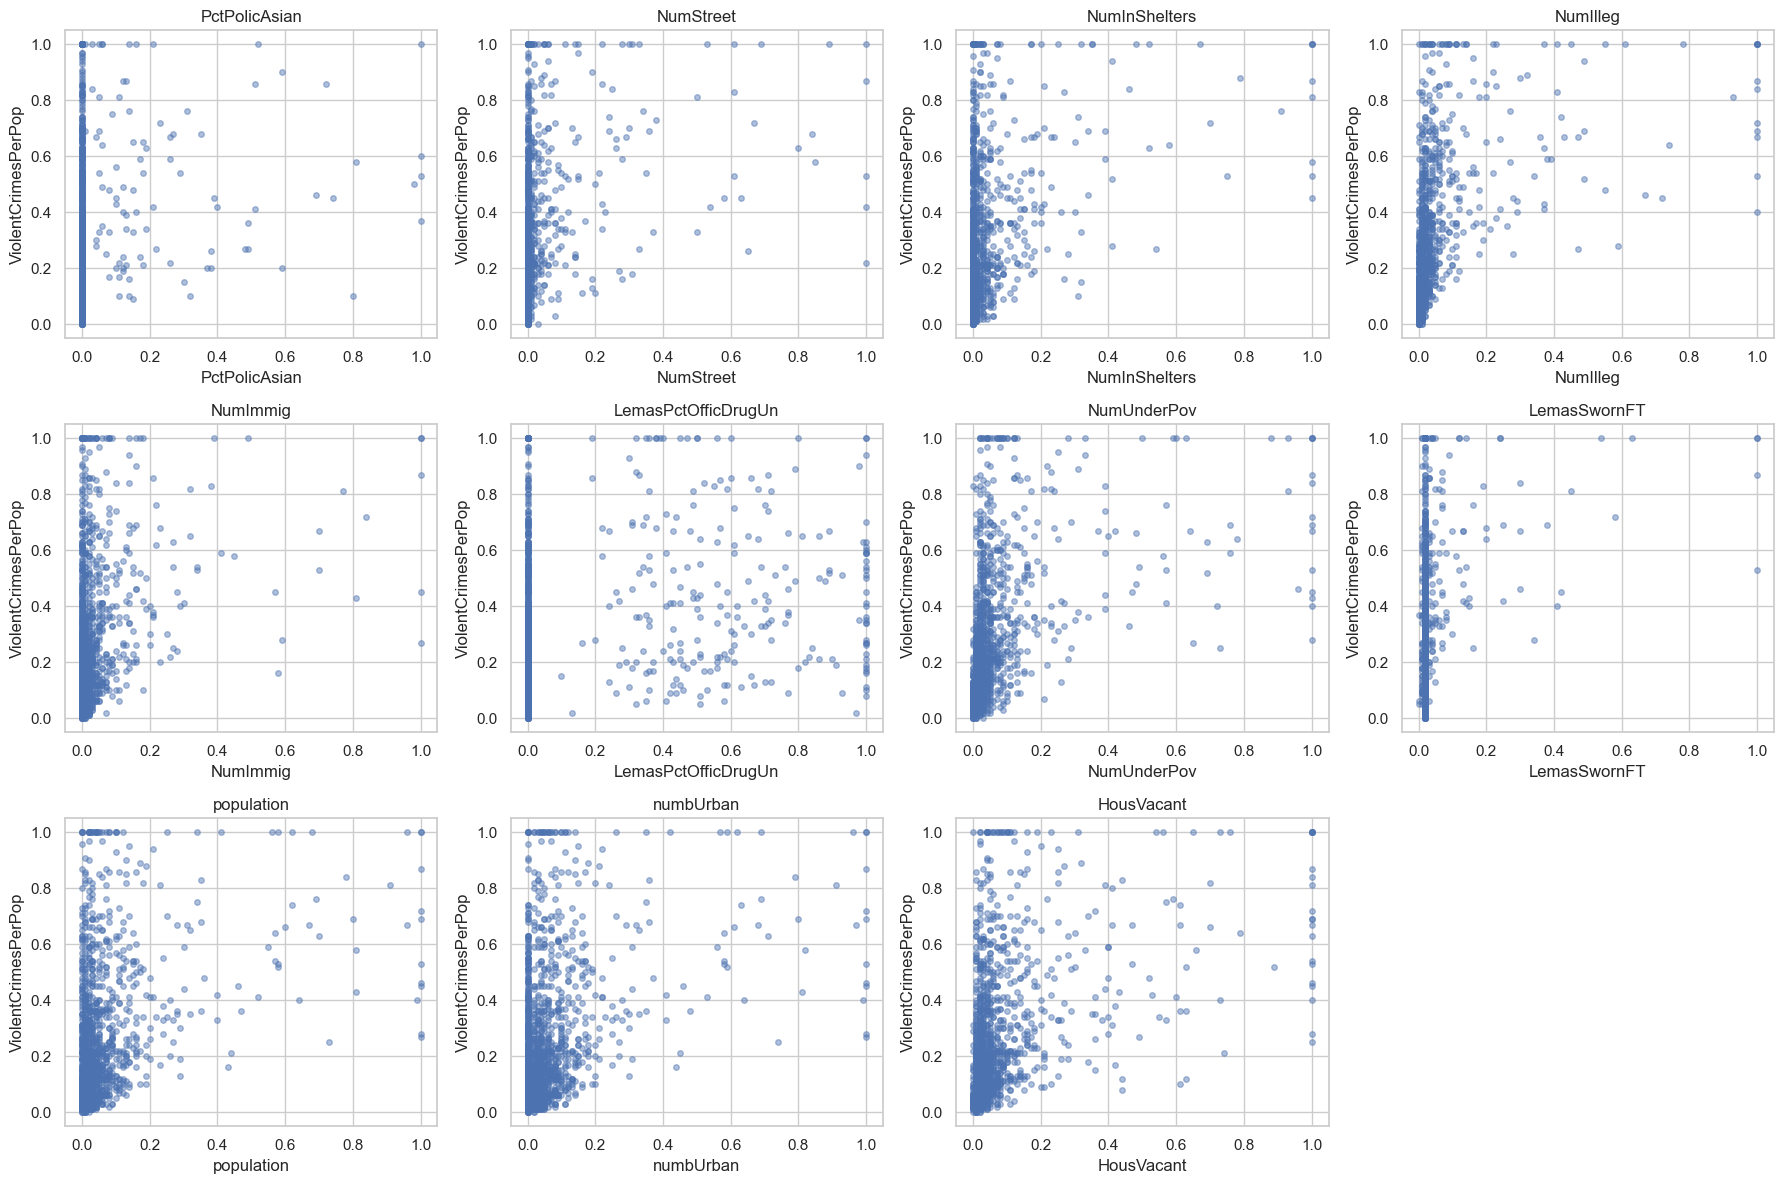

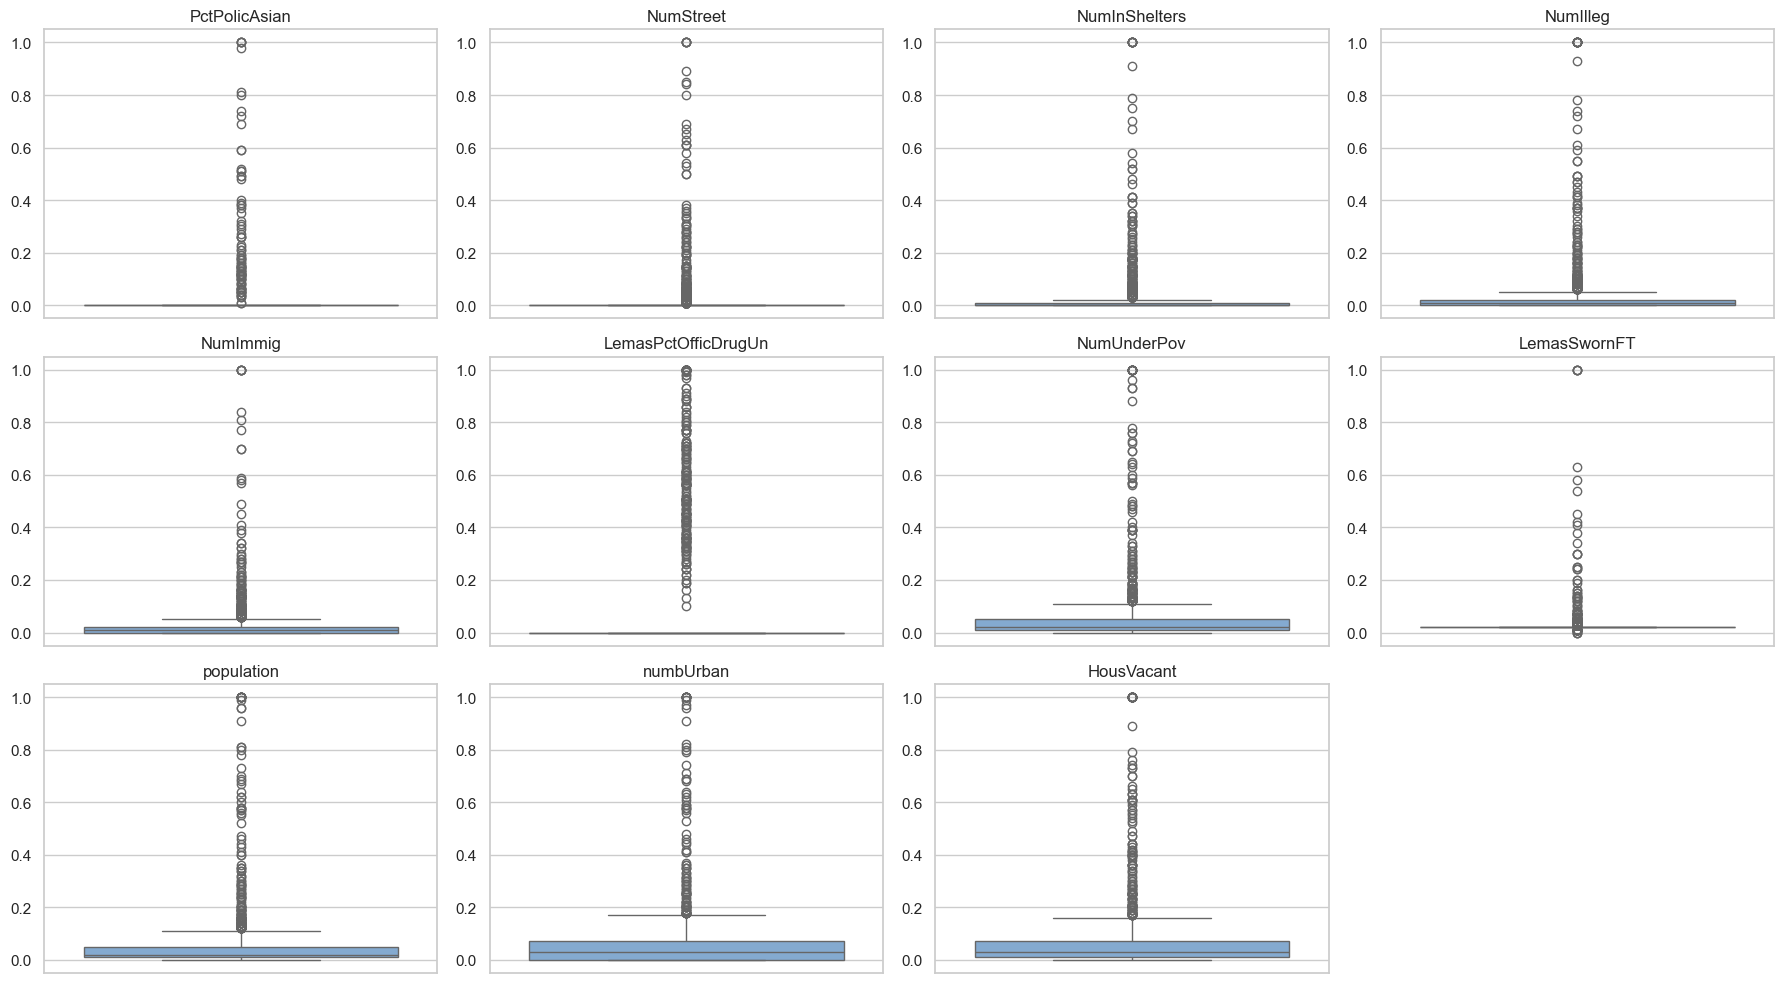

Conclusion: the scatter plots are descriptive only; they do not prove significance.


In [13]:
feature_cv = X_train.std(ddof=1) / X_train.mean()

top = (
    feature_cv
    .sort_values(ascending=False)
    .head(11)
    .index
    .tolist()
)

cv_table = pd.DataFrame(
    {
        'feature': top,
        'CV': feature_cv[top].values,
    }
)

display(cv_table.round(4))

fig, axes = plt.subplots(3, 4, figsize=(18, 12))

for ax, feature in zip(axes.ravel(), top):
    ax.scatter(
        X_train[feature],
        y_train,
        alpha=0.45,
        s=16,
    )
    ax.set_title(feature)
    ax.set_xlabel(feature)
    ax.set_ylabel(target)

for ax in axes.ravel()[len(top):]:
    ax.axis('off')

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(3, 4, figsize=(18, 10))

for ax, feature in zip(axes.ravel(), top):
    sns.boxplot(
        y=X_train[feature],
        ax=ax,
        color='#77aadd',
    )
    ax.set_title(feature)
    ax.set_ylabel('')

for ax in axes.ravel()[len(top):]:
    ax.axis('off')

plt.tight_layout()
plt.show()

print(
    'Conclusion: the scatter plots are descriptive only; '
    'they do not prove significance.'
)


## 2(f)-(j) Linear, Ridge, LASSO, PCR, and boosting models

For every model, the test error reported below is mean squared error (MSE).

- **2(f):** ordinary least squares is the baseline.
- **2(g):** Ridge chooses lambda by five-fold cross-validation.
- **2(h):** LASSO chooses lambda by five-fold cross-validation, first with the supplied values and then after standardizing the predictors. The selected variables are printed in the next section.
- **2(i):** PCR chooses the number of components $M$ by five-fold cross-validation.
- **2(j):** XGBoost uses reg_alpha for L1 regularization, and alpha is selected by five-fold cross-validation.

The cross-validation step uses training data only; the test set is used only for the final MSE.


In [14]:
results = []

ols = LinearRegression()
ols.fit(X_train, y_train)

results.append(
    [
        'Least squares',
        mean_squared_error(y_test, ols.predict(X_test)),
    ]
)

ridge = Pipeline(
    [
        ('scale', StandardScaler()),
        (
            'model',
            RidgeCV(
                alphas=np.logspace(-4, 4, 80),
                cv=cv,
                scoring='neg_mean_squared_error',
            ),
        ),
    ]
)
ridge.fit(X_train, y_train)

results.append(
    [
        'Ridge',
        mean_squared_error(y_test, ridge.predict(X_test)),
    ]
)

lasso = LassoCV(
    alphas=np.logspace(-5, 0, 100),
    cv=cv,
    random_state=RANDOM_STATE,
    max_iter=50000,
)
lasso.fit(X_train, y_train)

results.append(
    [
        'LASSO (provided scaling)',
        mean_squared_error(y_test, lasso.predict(X_test)),
    ]
)

standard_lasso = Pipeline(
    [
        ('scale', StandardScaler()),
        (
            'model',
            LassoCV(
                alphas=np.logspace(-5, 0, 100),
                cv=cv,
                random_state=RANDOM_STATE,
                max_iter=50000,
            ),
        ),
    ]
)
standard_lasso.fit(X_train, y_train)

results.append(
    [
        'LASSO (standardized)',
        mean_squared_error(
            y_test,
            standard_lasso.predict(X_test),
        ),
    ]
)

pcr = Pipeline(
    [
        ('scale', StandardScaler()),
        ('pca', PCA()),
        ('model', LinearRegression()),
    ]
)

pcr_grid = GridSearchCV(
    pcr,
    {'pca__n_components': list(range(1, 41))},
    cv=cv,
    scoring='neg_mean_squared_error',
    n_jobs=-1,
)
pcr_grid.fit(X_train, y_train)

results.append(
    [
        'PCR',
        mean_squared_error(y_test, pcr_grid.predict(X_test)),
    ]
)

xgb = XGBRegressor(
    objective='reg:squarederror',
    n_estimators=300,
    learning_rate=0.05,
    max_depth=3,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

xgb_grid = GridSearchCV(
    xgb,
    {'reg_alpha': [0, 0.001, 0.01, 0.1, 1.0, 10.0]},
    cv=cv,
    scoring='neg_mean_squared_error',
    n_jobs=-1,
)
xgb_grid.fit(X_train, y_train)

results.append(
    [
        'L1-penalized gradient boosting tree',
        mean_squared_error(y_test, xgb_grid.predict(X_test)),
    ]
)

result_table = pd.DataFrame(
    results,
    columns=['model', 'test_mse'],
).sort_values('test_mse')

display(result_table.round(5))

print('Ridge alpha:', ridge.named_steps['model'].alpha_)
print('LASSO alpha:', lasso.alpha_)
print(
    'Standardized LASSO alpha:',
    standard_lasso.named_steps['model'].alpha_,
)
print('PCR components:', pcr_grid.best_params_['pca__n_components'])
print('XGBoost alpha:', xgb_grid.best_params_['reg_alpha'])


,model,test_mse
5,L1-penalized gradient boosting tree,0.01632
1,Ridge,0.01744
2,LASSO (provided scaling),0.01768
3,LASSO (standardized),0.01774
0,Least squares,0.01797
4,PCR,0.01824


Ridge alpha: 74.71670675868081
LASSO alpha: 9.111627561154887e-05
Standardized LASSO alpha: 0.0005857020818056667
PCR components: 38
XGBoost alpha: 0


### LASSO selected variables and comparison


In [15]:
selected_unscaled = X_train.columns[
    np.abs(lasso.coef_) > 1e-8
].tolist()

selected_scaled = X_train.columns[
    np.abs(standard_lasso.named_steps['model'].coef_) > 1e-8
].tolist()

print(
    'Selected without extra standardization:',
    selected_unscaled,
)

print(
    'Selected after standardization:',
    selected_scaled,
)

print(
    'The two LASSO results can differ because the L1 penalty '
    'depends on feature scale, even though these features were '
    'already normalized by the data source.'
)


Selected without extra standardization: ['racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'agePct65up', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctBSorMore', 'PctEmploy', 'PctEmplManu', 'PctOccupManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PersPerOwnOccHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'MedNumBR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'OwnOccLowQuart', 'RentLowQ', 'MedRent', 'MedRentPctHousInc', 'MedOwnCostPctInc', 'MedOwnCostPctIncNoMtg', 'NumInShelters', 'NumStreet', '